# ETF prices and proposed universe

This notebook downloads daily adjusted prices for the 21 candidate ETFs, finds each ETF's first trading date, proposes the 18-ETF universe, and packs every output into one zip file for you to download. It also builds the company-to-sector-ETF mapping and the trading calendar function.

## 1. Create the output folders

Files are written to a folder called `etf_extraction` next to this notebook. In Colab this folder is temporary, so download the zip file in the last step before closing the tab.

In [4]:
import os
BASE = 'etf_extraction'
DATA = BASE + '/data'
RESULTS = BASE + '/results'
os.makedirs(DATA, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)
print('Saving to', os.path.abspath(BASE))

Saving to /content/etf_extraction


## 2. Define the candidate ETFs

`role` says how each ETF is used. `news_signal` says whether company news can be mapped to it. Bonds, gold, commodities and cash get no news signal and use historical volatility only.

In [5]:
import pandas as pd

universe = pd.DataFrame([
    ('XLK', 'Technology Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLF', 'Financial Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLE', 'Energy Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLV', 'Health Care Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLI', 'Industrial Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLY', 'Consumer Discretionary Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLP', 'Consumer Staples Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLU', 'Utilities Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('XLB', 'Materials Select Sector SPDR', 'Equity sector', 'Universe', 'Yes'),
    ('VNQ', 'Vanguard Real Estate ETF', 'Real estate', 'Universe', 'Yes'),
    ('VOX', 'Vanguard Communication Services ETF', 'Equity sector', 'Universe', 'Yes'),
    ('AGG', 'iShares Core U.S. Aggregate Bond ETF', 'Bond', 'Universe', 'No'),
    ('IEF', 'iShares 7-10 Year Treasury Bond ETF', 'Bond', 'Universe', 'No'),
    ('TLT', 'iShares 20+ Year Treasury Bond ETF', 'Bond', 'Universe', 'No'),
    ('LQD', 'iShares iBoxx $ Investment Grade Corporate Bond ETF', 'Bond', 'Universe', 'No'),
    ('GLD', 'SPDR Gold Shares', 'Gold', 'Universe', 'No'),
    ('DBC', 'Invesco DB Commodity Index Tracking Fund', 'Commodities', 'Universe', 'No'),
    ('BIL', 'SPDR Bloomberg 1-3 Month T-Bill ETF', 'Cash proxy', 'Universe', 'No'),
    ('SPY', 'SPDR S&P 500 ETF Trust', 'Broad equity', 'Benchmark only', 'No'),
    ('XLC', 'Communication Services Select Sector SPDR', 'Equity sector', 'Candidate (short history)', 'Yes'),
    ('XLRE', 'Real Estate Select Sector SPDR', 'Real estate', 'Candidate (short history)', 'Yes'),
], columns=['ticker', 'name', 'group', 'role', 'news_signal'])

universe.to_csv(DATA + '/etf_universe.csv', index=False)
universe

,ticker,name,group,role,news_signal
0,XLK,Technology Select Sector SPDR,Equity sector,Universe,Yes
1,XLF,Financial Select Sector SPDR,Equity sector,Universe,Yes
2,XLE,Energy Select Sector SPDR,Equity sector,Universe,Yes
3,XLV,Health Care Select Sector SPDR,Equity sector,Universe,Yes
4,XLI,Industrial Select Sector SPDR,Equity sector,Universe,Yes
5,XLY,Consumer Discretionary Select Sector SPDR,Equity sector,Universe,Yes
6,XLP,Consumer Staples Select Sector SPDR,Equity sector,Universe,Yes
7,XLU,Utilities Select Sector SPDR,Equity sector,Universe,Yes
8,XLB,Materials Select Sector SPDR,Equity sector,Universe,Yes
9,VNQ,Vanguard Real Estate ETF,Real estate,Universe,Yes


## 3. Download daily adjusted prices

`auto_adjust=True` makes `Close` the adjusted close, which includes dividends and splits. The end date matches the last year covered by FNSPID (2023).

In [6]:
!pip install -q yfinance
import yfinance as yf

tickers = universe['ticker'].tolist()
raw = yf.download(tickers, start='1998-01-01', end='2024-01-01', auto_adjust=True, progress=False)
prices = raw['Close'][tickers].sort_index()
prices.index.name = 'date'

missing = [t for t in tickers if prices[t].notna().sum() == 0]
print('Rows:', len(prices), '| Columns:', prices.shape[1])
print('Tickers with no data:', missing if missing else 'none')

prices.to_csv(DATA + '/etf_prices.csv')
prices.tail()

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VNQ']: OperationalError('database is locked')


Rows: 6541 | Columns: 21
Tickers with no data: ['VNQ']


Ticker,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,VNQ,...,AGG,IEF,TLT,LQD,GLD,DBC,BIL,SPY,XLC,XLRE
date,,,,,,,,,,,,,,,,,,,,,
2023-12-22,94.439857,35.819782,39.023396,129.012390,109.089249,87.691490,66.156708,28.900312,40.693336,NaN,...,88.853127,86.762070,87.511383,97.255562,190.270004,20.416229,81.176086,458.641022,70.313591,36.229259
2023-12-26,94.833267,35.963680,39.358620,129.299072,109.860664,88.062828,66.435379,29.075691,40.883499,NaN,...,89.032921,86.816193,87.760178,97.458755,191.720001,20.618279,81.193863,460.577606,70.584740,36.493713
2023-12-27,94.828339,36.078796,39.184124,129.843689,110.024582,88.365746,66.741920,29.057230,40.983322,NaN,...,89.599327,87.492691,89.315277,98.368576,192.589996,20.526438,81.193863,461.410431,70.594414,36.703442
2023-12-28,94.941444,36.184311,38.587154,130.178131,110.053513,87.906456,66.769783,29.264912,40.826450,NaN,...,89.401512,87.158943,88.666565,98.112411,191.470001,20.351940,81.247208,461.584747,70.788086,36.931416
2023-12-29,94.651306,36.069199,38.499905,130.311874,109.918510,87.364159,66.909126,29.227991,40.664810,NaN,...,89.230690,86.942490,87.866791,97.750237,191.169998,20.241732,81.247208,460.248474,70.362000,36.530190


## 4. First trading date of each ETF

The youngest ETF in the universe decides the earliest possible backtest start.

In [7]:
start_dates = pd.DataFrame({
    'first_date': prices.apply(lambda col: col.first_valid_index()),
    'last_date': prices.apply(lambda col: col.last_valid_index()),
    'trading_days': prices.notna().sum(),
})
start_dates = universe.set_index('ticker')[['group', 'role']].join(start_dates).sort_values('first_date')
start_dates.to_csv(RESULTS + '/etf_start_dates.csv')
start_dates

,group,role,first_date,last_date,trading_days
ticker,,,,,
SPY,Broad equity,Benchmark only,1998-01-02,2023-12-29,6541
XLK,Equity sector,Universe,1998-12-22,2023-12-29,6296
XLF,Equity sector,Universe,1998-12-22,2023-12-29,6296
XLE,Equity sector,Universe,1998-12-22,2023-12-29,6296
XLV,Equity sector,Universe,1998-12-22,2023-12-29,6296
XLI,Equity sector,Universe,1998-12-22,2023-12-29,6296
XLY,Equity sector,Universe,1998-12-22,2023-12-29,6296
XLP,Equity sector,Universe,1998-12-22,2023-12-29,6296
XLU,Equity sector,Universe,1998-12-22,2023-12-29,6296


## 5. Data quality check

Empty cells should appear only before an ETF started. A gap in the middle of a series needs investigating.

In [8]:
def gaps_inside(col):
    first, last = col.first_valid_index(), col.last_valid_index()
    if first is None:
        return None
    return int(col.loc[first:last].isna().sum())

quality = pd.DataFrame({
    'gaps_inside_history': prices.apply(gaps_inside),
    'min_price': prices.min(),
    'max_price': prices.max(),
})
print('Duplicate dates:', int(prices.index.duplicated().sum()))
quality

Duplicate dates: 0


,gaps_inside_history,min_price,max_price
Ticker,,,
XLK,0.0,4.298373,94.941444
XLF,0.0,3.654650,38.193054
XLE,0.0,5.108232,42.152630
XLV,0.0,14.665953,132.592133
XLI,0.0,10.977810,110.053513
XLY,0.0,6.462529,101.374077
XLP,0.0,9.790575,71.385658
XLU,0.0,3.324768,34.374428
XLB,0.0,4.810519,41.358643


## 6. Proposed universe and backtest window

The proposal is the 18 ETFs with role `Universe`. VOX covers Communication Services, because XLC only started in 2018. SPY is kept as a benchmark only. XLC and XLRE are left out because of their short history. The common start date is the first date on which all 18 have a price.

In [9]:
proposed = universe.loc[universe['role'] == 'Universe', 'ticker'].tolist()
common_start = prices[proposed].apply(lambda col: col.first_valid_index()).max()
common_end = prices[proposed].apply(lambda col: col.last_valid_index()).min()
print('Proposed universe:', len(proposed), 'ETFs')
print('Common window:', common_start.date(), 'to', common_end.date())

# What the window would be if XLC were included
with_xlc = proposed + ['XLC']
print('Start if XLC is included:', prices[with_xlc].apply(lambda col: col.first_valid_index()).max().date())

prices_universe = prices.loc[common_start:common_end, proposed + ['SPY']]
prices_universe.to_csv(DATA + '/etf_prices_universe.csv')

Proposed universe: 18 ETFs
Common window: 2007-05-30 to 2023-12-29
Start if XLC is included: 2018-06-19


## 7. Daily returns and a sanity check

Annualised volatility should be lowest for BIL, low for bonds, and higher for equity sectors. If it is not, something is wrong with the data.

In [10]:
import numpy as np

returns = np.log(prices_universe / prices_universe.shift(1)).dropna(how='all')
returns.to_csv(DATA + '/etf_returns_universe.csv')

summary = pd.DataFrame({
    'annualised_volatility': returns.std() * np.sqrt(252),
    'annualised_mean_return': returns.mean() * 252,
}).sort_values('annualised_volatility')
summary.to_csv(RESULTS + '/etf_volatility_summary.csv')
summary.round(4)

,annualised_volatility,annualised_mean_return
Ticker,,
BIL,0.0051,0.0090
AGG,0.0551,0.0293
IEF,0.0713,0.0334
LQD,0.0917,0.0413
XLP,0.1493,0.0846
TLT,0.1556,0.0375
GLD,0.1751,0.0654
XLV,0.1766,0.0969
XLU,0.1964,0.0610


## 8. Charts

Prices are rebased to 100 at the common start date so the ETFs can be compared on one chart.

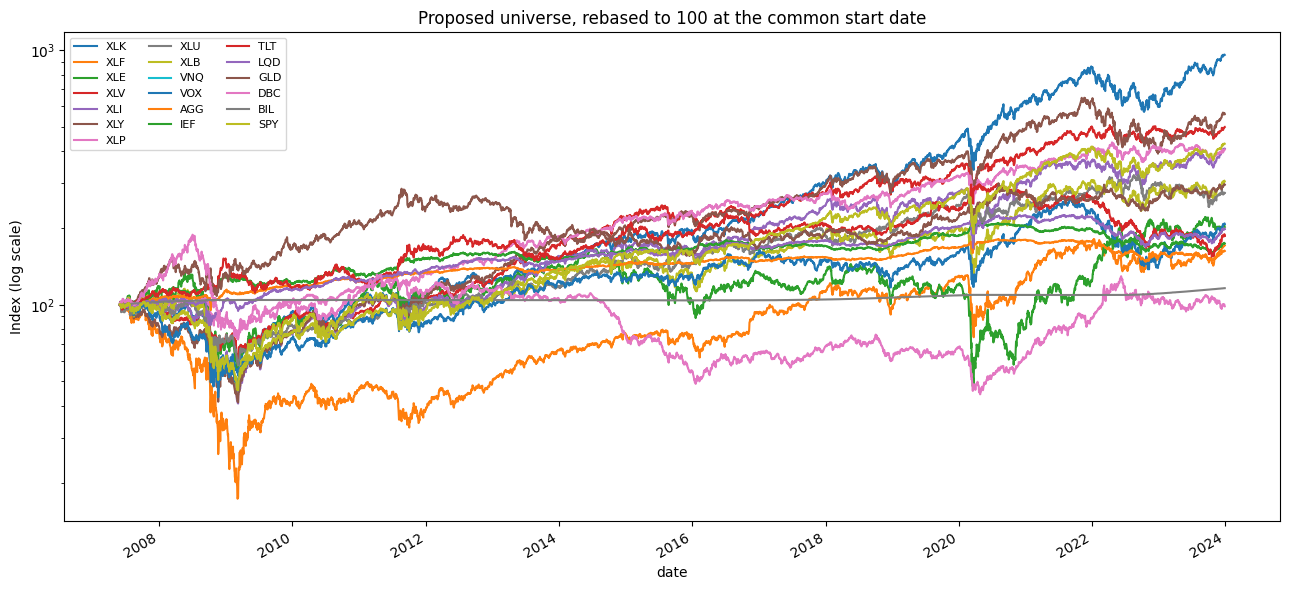

In [11]:
import matplotlib.pyplot as plt

rebased = prices_universe / prices_universe.iloc[0] * 100
ax = rebased.plot(figsize=(13, 6), logy=True, title='Proposed universe, rebased to 100 at the common start date')
ax.set_ylabel('Index (log scale)')
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS + '/etf_prices_rebased.png', dpi=150)
plt.show()

## 9. Sector-to-ETF rule for the company mapping

This is the rule used later to map each company in the news data to one sector ETF through its GICS sector. Communication Services maps to VOX, which has a longer history than XLC, so that news is kept.

In [12]:
sector_to_etf = pd.DataFrame([
    ('Information Technology', 'XLK'),
    ('Financials', 'XLF'),
    ('Energy', 'XLE'),
    ('Health Care', 'XLV'),
    ('Industrials', 'XLI'),
    ('Consumer Discretionary', 'XLY'),
    ('Consumer Staples', 'XLP'),
    ('Utilities', 'XLU'),
    ('Materials', 'XLB'),
    ('Real Estate', 'VNQ'),
    ('Communication Services', 'VOX'),
], columns=['gics_sector', 'sector_etf'])
sector_to_etf['in_proposed_universe'] = sector_to_etf['sector_etf'].isin(proposed)
sector_to_etf.to_csv(DATA + '/sector_to_etf.csv', index=False)
sector_to_etf

,gics_sector,sector_etf,in_proposed_universe
0,Information Technology,XLK,True
1,Financials,XLF,True
2,Energy,XLE,True
3,Health Care,XLV,True
4,Industrials,XLI,True
5,Consumer Discretionary,XLY,True
6,Consumer Staples,XLP,True
7,Utilities,XLU,True
8,Materials,XLB,True
9,Real Estate,VNQ,True


## 10. Company-to-sector-ETF mapping (task 17)

**Source:** the daily holdings file of the iShares Core S&P 500 ETF (IVV), published by BlackRock iShares. IVV holds every S&P 500 company and lists each one's GICS sector. (State Street's SPY file was tried first, but its automatic download returns an empty file.)

The cell downloads the CSV automatically and keeps the copy as `ivv_holdings.csv`. Only if the download fails does it ask you to upload the file yourself: open the link it prints in your browser, save the file, and choose it.

**List date:** the "Fund Holdings as of" date at the top of the file. It is saved with every row.

Two spelling fixes: iShares writes "Communication" for Communication Services, and "BRKB" / "BFB" for BRK.B / BF.B.

Reference: BlackRock iShares (2026). *iShares Core S&P 500 ETF (IVV) holdings*. ishares.com.

In [13]:
import io, re
import requests

IVV_URL = 'https://www.ishares.com/us/products/239726/ishares-core-s-p-500-etf/latest-holdings.csv'
IVV_FILE = DATA + '/ivv_holdings.csv'

if not os.path.exists(IVV_FILE):                      # download once, then keep this copy
    try:
        r = requests.get(IVV_URL, headers={'User-Agent': 'Mozilla/5.0'}, timeout=60)
        r.raise_for_status()
        open(IVV_FILE, 'wb').write(r.content)
        print('Downloaded the IVV holdings file from iShares')
    except Exception as e:
        print('Automatic download failed:', e)
        print('Open the link below in your browser, save the file, and choose it when asked:\n', IVV_URL)
        from google.colab import files
        uploaded = files.upload()
        os.rename(list(uploaded)[0], IVV_FILE)

text = open(IVV_FILE, encoding='utf-8-sig').read()
lines = text.splitlines()

# The list date is on the line "Fund Holdings as of,"Oct 16, 2026""
date_line = next(l for l in lines if l.startswith('Fund Holdings as of'))
list_date = pd.to_datetime(re.search(r'"(.+)"', date_line).group(1)).date()

# The table starts at the line that begins with "Ticker,"; keep only the company (equity) rows
header = next(i for i, l in enumerate(lines) if l.startswith('Ticker,'))
holdings = pd.read_csv(io.StringIO(text), skiprows=header, on_bad_lines='skip')
holdings = holdings[holdings['Asset Class'] == 'Equity']

sp500 = pd.DataFrame({'ticker': holdings['Ticker'].astype(str).str.strip(),
                      'company': holdings['Name'],
                      'gics_sector': holdings['Sector'].replace({'Communication': 'Communication Services'})})
sp500['ticker'] = sp500['ticker'].replace({'BRKB': 'BRK.B', 'BFB': 'BF.B'}).str.upper().str.replace(r'[- ]', '.', regex=True)
sp500 = sp500.drop_duplicates('ticker')

# Company -> sector -> ETF, using the rule from section 9
sp500 = sp500.merge(sector_to_etf, on='gics_sector', how='left')
sp500['list_date'] = list_date
sp500['source'] = 'iShares Core S&P 500 ETF (IVV) holdings'
assert len(sp500) >= 400, f'Only {len(sp500)} companies: open {IVV_FILE} and check it'
sp500.to_csv(DATA + '/sp500_sectors.csv', index=False)

print('Companies:', len(sp500), '| list date:', list_date)
print('Companies with no ETF (should be 0):', sp500['sector_etf'].isna().sum())
sp500.groupby(['sector_etf', 'gics_sector', 'in_proposed_universe']).size().rename('companies')


Downloaded the IVV holdings file from iShares
Companies: 504 | list date: 2026-10-16
Companies with no ETF (should be 0): 0


,,,companies
sector_etf,gics_sector,in_proposed_universe,
VNQ,Real Estate,True,30
VOX,Communication Services,True,22
XLB,Materials,True,24
XLE,Energy,True,21
XLF,Financials,True,76
XLI,Industrials,True,83
XLK,Information Technology,True,75
XLP,Consumer Staples,True,34
XLU,Utilities,True,31


## 11. Trading calendar function (task 18)

FNSPID times are in UTC, e.g. `2020-03-10 21:30:00 UTC`. A headline belongs to a trading day as follows:
- published **before that day's close** (16:00 New York, 13:00 on half-days) → that day
- published **after the close, on a weekend or on a holiday** → the next trading day
- **no time of day** (shown as `00:00:00`) → the next trading day after its date. This is the safe choice: the news might have come out after the close, so we never use it too early.

The NYSE calendar from `pandas_market_calendars` gives the trading days and close times, including half-days and holidays.

In [14]:
!pip install -q pandas_market_calendars
import pandas_market_calendars as mcal

schedule = mcal.get_calendar('NYSE').schedule(start_date='1998-01-01', end_date='2024-01-31')
schedule.index = pd.to_datetime(schedule.index)
schedule['close_ny'] = schedule['market_close'].dt.tz_convert('America/New_York')
trading_days = schedule.index
schedule[['close_ny']].to_csv(DATA + '/trading_calendar.csv')

print('Trading days:', len(trading_days), '| half-days:', (schedule['close_ny'].dt.hour < 16).sum())
print('Price dates missing from the calendar (should be 0):', len(prices.index.difference(trading_days)))

def to_trading_day(published):
    """FNSPID time such as '2020-03-10 21:30:00 UTC' -> the trading day the news belongs to."""
    t = pd.Timestamp(published.replace(' UTC', ''), tz='UTC')
    if t.hour == 0 and t.minute == 0 and t.second == 0:     # no time of day recorded
        day = pd.Timestamp(t.date())
        return trading_days[trading_days > day][0]           # next trading day
    t_ny = t.tz_convert('America/New_York')
    day = pd.Timestamp(t_ny.date())
    if day in trading_days and t_ny < schedule.loc[day, 'close_ny']:
        return day                                            # before the close: same day
    return trading_days[trading_days > day][0]                # after close, weekend or holiday

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.1/141.1 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.3/213.3 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 4.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires toolz<1,>=0.11, but you have toolz 1.2.0 which is incompatible.
Trading days: 6562 | half-days: 56
Price dates missing from the calendar (should be 0): 0


### Test on six hand-picked cases

In [15]:
tests = pd.DataFrame([
    ('1 During trading hours',    '2020-03-10 15:00:00 UTC', '2020-03-10'),
    ('2 After the 16:00 close',   '2020-03-10 21:30:00 UTC', '2020-03-11'),
    ('3 Friday night -> Monday',  '2021-01-08 22:00:00 UTC', '2021-01-11'),
    ('4 Holiday (Christmas)',     '2019-12-25 15:00:00 UTC', '2019-12-26'),
    ('5 Half-day, closed 13:00',  '2019-11-29 19:00:00 UTC', '2019-12-02'),
    ('6 No time of day recorded', '2020-05-22 00:00:00 UTC', '2020-05-26'),
], columns=['case', 'published_utc', 'expected'])

tests['new_york_time'] = [pd.Timestamp(p.replace(' UTC', ''), tz='UTC').tz_convert('America/New_York').strftime('%a %d %b %Y %H:%M')
                          for p in tests['published_utc']]
tests['result'] = [to_trading_day(p).strftime('%Y-%m-%d') for p in tests['published_utc']]
tests['pass'] = tests['result'] == tests['expected']
tests.to_csv(RESULTS + '/trading_calendar_tests.csv', index=False)

assert tests['pass'].all(), 'A test failed: check the table'
print('All 6 tests pass')
tests

All 6 tests pass


,case,published_utc,expected,new_york_time,result,pass
0,1 During trading hours,2020-03-10 15:00:00 UTC,2020-03-10,Tue 10 Mar 2020 11:00,2020-03-10,True
1,2 After the 16:00 close,2020-03-10 21:30:00 UTC,2020-03-11,Tue 10 Mar 2020 17:30,2020-03-11,True
2,3 Friday night -> Monday,2021-01-08 22:00:00 UTC,2021-01-11,Fri 08 Jan 2021 17:00,2021-01-11,True
3,4 Holiday (Christmas),2019-12-25 15:00:00 UTC,2019-12-26,Wed 25 Dec 2019 10:00,2019-12-26,True
4,"5 Half-day, closed 13:00",2019-11-29 19:00:00 UTC,2019-12-02,Fri 29 Nov 2019 14:00,2019-12-02,True
5,6 No time of day recorded,2020-05-22 00:00:00 UTC,2020-05-26,Thu 21 May 2020 20:00,2020-05-26,True


## 12. Download everything as one zip file

This packs the `etf_extraction` folder into `etf_extraction.zip`. In Colab the browser download starts automatically. Anywhere else, the zip file is saved next to this notebook.

| File | Folder | Use |
|---|---|---|
| `etf_universe.csv` | data | The 21 candidates with their role |
| `etf_prices.csv` | data | Daily adjusted close, all 21 |
| `etf_prices_universe.csv` | data | The 18 proposed ETFs plus SPY, common window only |
| `etf_returns_universe.csv` | data | Daily log returns |
| `sector_to_etf.csv` | data | Mapping rule for the news data |
| `etf_start_dates.csv` | results | Table for the meeting |
| `etf_volatility_summary.csv` | results | Sanity check |
| `etf_prices_rebased.png` | results | Chart for the midterm form |
| `sp500_sectors.csv` | data | Task 17: every S&P 500 company with its sector ETF and list date |
| `trading_calendar.csv` | data | Task 18: trading days and close times |
| `trading_calendar_tests.csv` | results | Task 18: the six test cases |

In [16]:
import shutil
zip_path = shutil.make_archive('etf_extraction', 'zip', BASE)
print('Created', zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Not running in Colab. The zip file is in the same folder as this notebook.')

Created /content/etf_extraction.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>